In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import dask

In [2]:
var = 't2m'
var_file = '2t'
year_min = 2016
year_max = 2016
path_original = '/work/uo1075/u244085/cerra_data/'+var+"/"
path_NN = '/work/uo1075/u244085/trees_in_the_city/ML_downscaling/Physics-Informed-CNN-Reconstructions/evaluations/t2m/cerra-germany-0.05x0.05-sorted/data/'


In [23]:
# Only keep years with 365 days, remove leap year day
def remove_leap_days(ds):
    # Get day-of-year for each time step
    day_of_year = ds['time'].dt.dayofyear
    # Keep only days <= 365 (i.e., remove Feb 29)
    ds_corrected = ds.sel(time=day_of_year <= 365)
    return ds_corrected

In [3]:
def compute_mse_year(file_nn, file_ref, var_file):

    ds_ref = xr.open_dataset(file_ref, chunks=chunks)[var_file]
    # ds_ref = ds_ref.rename({'valid_time': 'time'})
    # remove Feb 29
    ds_ref = remove_leap_days(ds_ref) #leap years to 365
    
    ds_nn = xr.open_dataset(file_nn, chunks=chunks)[var_file]
    #time dimension of NN output is wrong, with constant year time dimension. Correct it:
    ds_nn['time'] = ds_ref['time']

    #mask ocean data
    ds_nn = xr.where(np.isnan(ds_ref),np.nan,ds_nn)
    
    # Align
    ds_nn, ds_ref = xr.align(ds_nn, ds_ref)

    # Compute squared error lazily
    mse = ((ds_nn - ds_ref) ** 2).mean(dim="time", skipna=True)

    valid = (~np.isnan(ds_nn)) & (~np.isnan(ds_ref))
    n = valid.sum("time")

    return mse, n

In [7]:
chunks = {"time": 30, "lat": 150, "lon": 150}

In [8]:
year = 2016

In [9]:
file_nn = f"{path_NN}cerra_dm_{var}_ger_{year}_crai_output.nc"
file_ref = f"{path_original}cerra_dm_{var}_ger_{year}.nc"

In [10]:
ds_ref = xr.open_dataset(file_ref, chunks=chunks)[var_file]
# ds_ref = ds_ref.rename({'valid_time': 'time'})
# remove Feb 29
#ds_ref = remove_leap_days(ds_ref) #leap years to 365

ds_nn = xr.open_dataset(file_nn, chunks=chunks)[var_file]

In [11]:
ds_nn

<xarray.DataArray '2t' (time: 365, lat: 201, lon: 241)> Size: 71MB
dask.array<open_dataset-2t, shape=(365, 201, 241), dtype=float32, chunksize=(30, 150, 150), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 3kB 2016-01-01 10:30:00 ... 2016-12-31 10:30:00
  * lat      (lat) float64 2kB 46.0 46.05 46.1 46.15 ... 55.85 55.9 55.95 56.0
  * lon      (lon) float64 2kB 4.0 4.05 4.1 4.15 4.2 ... 15.85 15.9 15.95 16.0

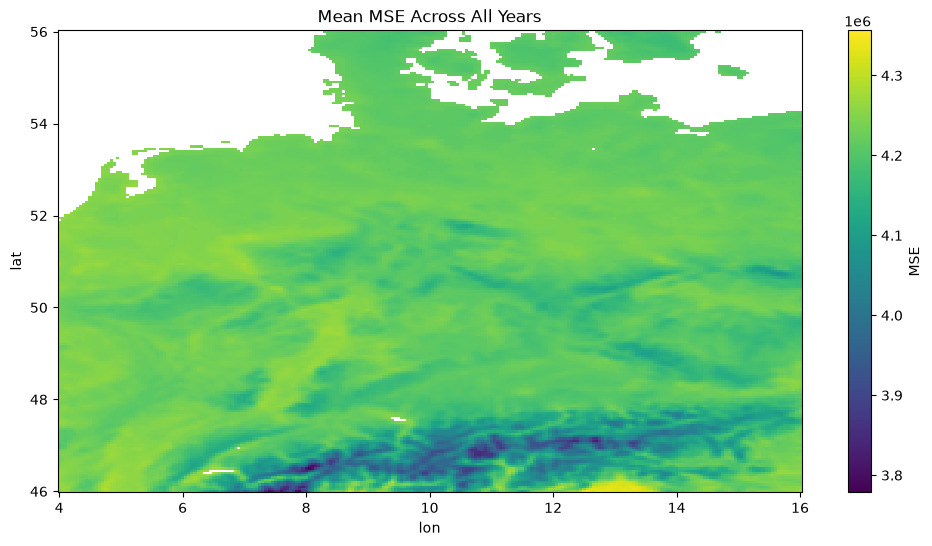

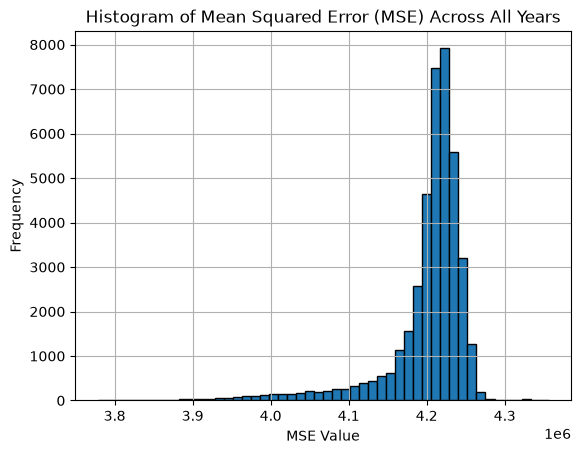

TypeError: unsupported format string passed to Array.__format__

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# Your existing paths
path_original = '/work/uo1075/u244085/cerra_data/'+var+"/"
path_NN = f'/work/uo1075/u244085/trees_in_the_city/ML_downscaling/Physics-Informed-CNN-Reconstructions/evaluations/{var}/cerra-germany-0.05x0.05-el5-all-var-l0/data/'

# Initialize
mse_maps = []
all_mse_values = []
sum_sq = 0
n_total = 0

for year in range(year_min, year_max + 1):
    file_nn = f"{path_NN}cerra_dm_{var}_ger_{year}_crai_output.nc"
    file_ref = f"{path_original}cerra_dm_{var}_ger_{year}.nc"
    # Compute MSE for the current year
    mse, n = compute_mse_year(file_nn, file_ref, var_file)
    mse_maps.append(mse)

    # Collect MSE values for histogram
    all_mse_values.extend(mse.values.flatten())

    # Accumulate for RMSE
    sum_sq += mse.sum()
    n_total += n.sum()

# --- Plot map of mean MSE across all years ---
mean_mse = xr.concat(mse_maps, dim='year').mean(dim='year')
mean_mse.plot(
    figsize=(12, 6),
    cbar_kwargs={'label': 'MSE'},
    cmap='viridis'
)
plt.title('Mean MSE Across All Years')
plt.show()

# --- Plot histogram of all MSE values ---
plt.hist(all_mse_values, bins=50, edgecolor='black')
plt.title('Histogram of Mean Squared Error (MSE) Across All Years')
plt.xlabel('MSE Value')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

# --- Calculate and print RMSE ---
rmse = np.sqrt(sum_sq / n_total)
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

In [21]:
print(rmse)

<xarray.DataArray 'tp' ()> Size: 8B
dask.array<sqrt, shape=(), dtype=float64, chunksize=(), chunktype=numpy.ndarray>
Attributes:
    long_name:  Total Precipitation
    units:      kg m**-2
    param:      52.1.0


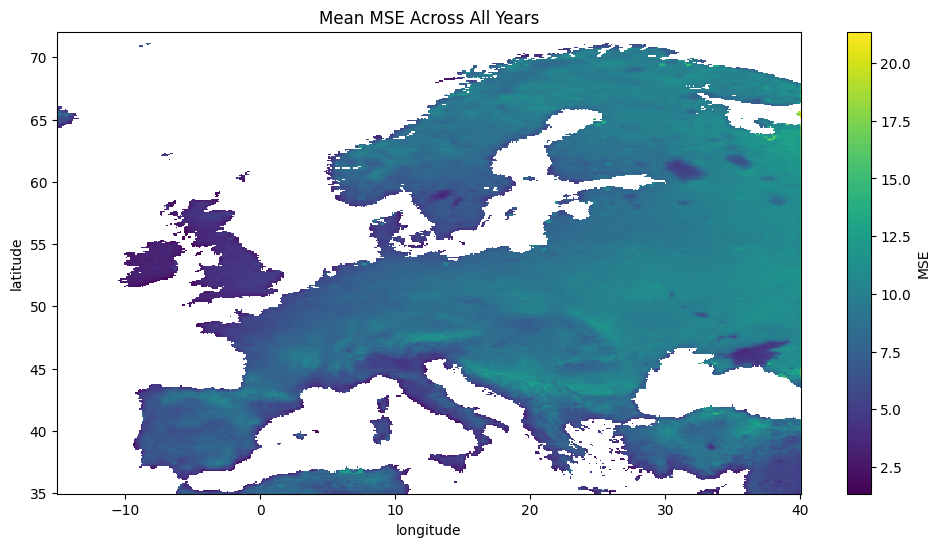

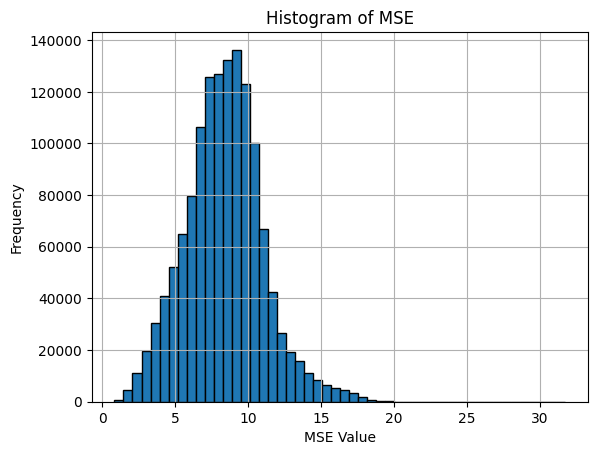

TypeError: unsupported format string passed to Array.__format__

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# def remove_leap_days(ds):
#     # Remove Feb 29 from the dataset
#     return ds.sel(time=~((ds.time.dt.month == 2) & (ds.time.dt.day == 29)))

def compute_mse_year(file_nn, file_ref, var_file, chunks=None):
    ds_ref = xr.open_dataset(file_ref, chunks=chunks)[var_file]
    ds_ref = remove_leap_days(ds_ref)

    ds_nn = xr.open_dataset(file_nn, chunks=chunks)[var_file]
    ds_nn['time'] = ds_ref['time']

    # Mask ocean data
    ds_nn = xr.where(np.isnan(ds_ref), np.nan, ds_nn)

    # Align
    ds_nn, ds_ref = xr.align(ds_nn, ds_ref)

    # Compute squared error
    mse = ((ds_nn - ds_ref) ** 2).mean(dim="time", skipna=True)
    valid = (~np.isnan(ds_nn)) & (~np.isnan(ds_ref))
    n = valid.sum("time")

    return mse, n


path_original = '/work/uo1075/u244085/cerra_data/'+var+"/"
path_NN = '/work/uo1075/u244085/trees_in_the_city/ML_downscaling/Physics-Informed-CNN-Reconstructions/evaluations/t2m/cerra-europe-0.05x0.05/data/'

mse_maps = []
all_mse_values = []
sum_sq = 0
n_total = 0

for year in range(year_min, year_max + 1):
    file_nn = f"{path_NN}cerra_dm_{var}_{year}_lowres_values_in_highres_grid_output.nc"
    file_ref = f"{path_original}cerra_dm_{var}_{year}.nc"
    mse, n = compute_mse_year(file_nn, file_ref, var_file, chunks=chunks)
    mse_maps.append(mse)
    all_mse_values.extend(mse.values.flatten())
    sum_sq += mse.sum()
    n_total += n.sum()



In [ ]:
plt.pcolormesh(rmse.longitude,rmse.latitude,rmse)
plt.colorbar()

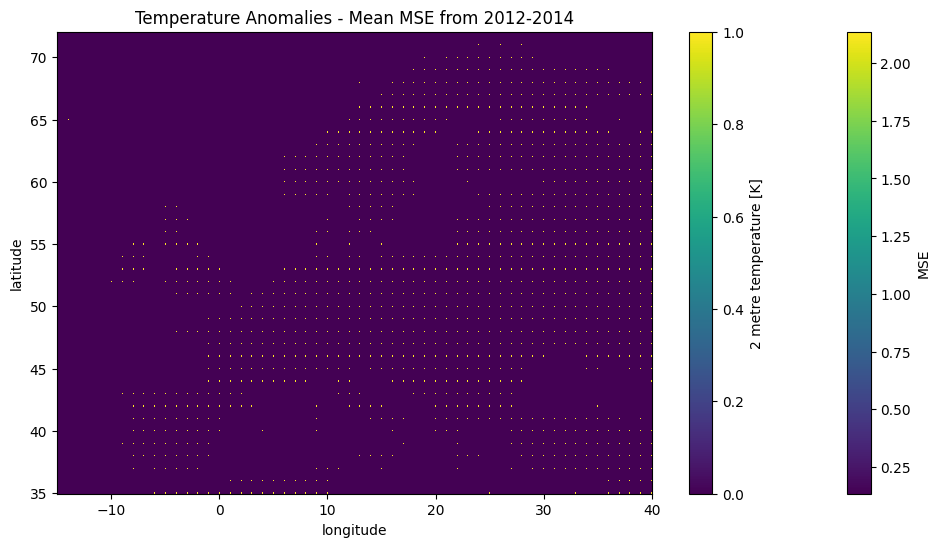

In [33]:
# Plot mean MSE
mean_mse = xr.concat(mse_maps, dim='year').mean(dim='year')*0.1
mean_mse.plot(figsize=(12, 6), cbar_kwargs={'label': 'MSE'}, cmap='viridis')
mask = xr.open_mfdataset("/work/uo1075/u244085/trees_in_the_city/data/era5_land/t2max/mask/era5_land_t2max_daily_2024_europe_binary_mask.nc")[var_file]
mask.isel(time=1).plot()
plt.title('Temperature Anomalies - Mean MSE from 2012-2014')
plt.show()

# Plot histogram
# plt.hist(all_mse_values, bins=50, edgecolor='black')
# plt.title('Histogram of MSE')
# plt.xlabel('MSE Value')
# plt.ylabel('Frequency')
# plt.grid(True)
# plt.show()

# # Calculate and print RMSE
# rmse = np.sqrt(sum_sq / n_total)
# print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# # Plot RMSE
# plt.figure()
# plt.text(0.5, 0.5, f"RMSE: {rmse:.4f}", fontsize=16, ha='center')
# plt.axis('off')
# plt.show()

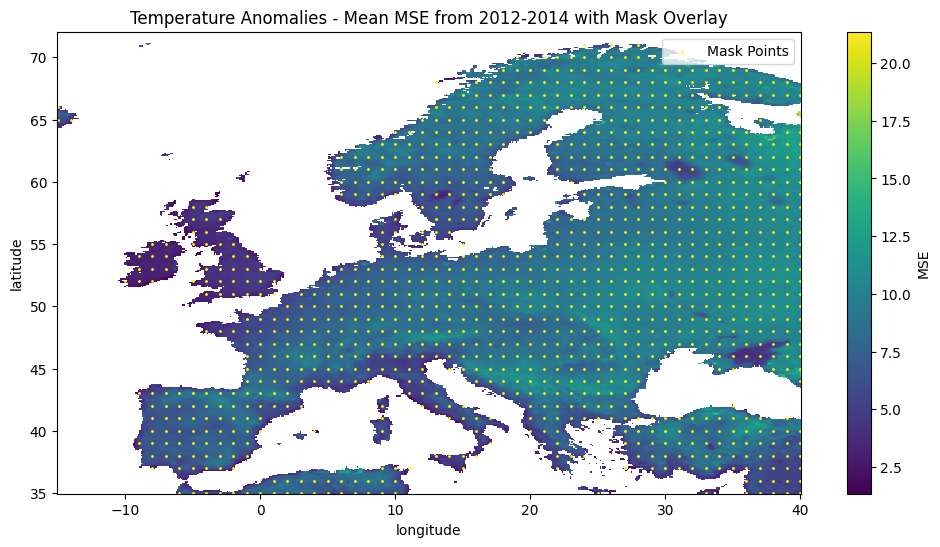

In [38]:
# Your existing code
mean_mse = xr.concat(mse_maps, dim='year').mean(dim='year')
mask = xr.open_mfdataset("/work/uo1075/u244085/trees_in_the_city/data/era5_land/t2max/mask/era5_land_t2max_daily_2024_europe_binary_mask.nc")[var_file]

# Plot mean MSE
fig, ax = plt.subplots(figsize=(12, 6))
mean_mse.plot(ax=ax, cbar_kwargs={'label': 'MSE'}, cmap='viridis')

# Overlay mask dots where mask == 1 (or True)
mask_sel = mask.isel(time=1)  # Select the time slice you want
lon = mask_sel.longitude  # or 'longitude', check your actual coordinate name
lat = mask_sel.latitude  # or 'latitude'
mask_values = mask_sel.values

# Plot dots for mask == 1
mask_points = np.where(mask_values == 1)
ax.scatter(
    lon[mask_points[1]],  # x-coordinates (longitude)
    lat[mask_points[0]],  # y-coordinates (latitude)
    color='yellow',           # Choose a color that stands out
    s=1,                   # Size of the dots
    alpha=1,             # Transparency
    label='Mask Points'
)

plt.title('Temperature Anomalies - Mean MSE from 2012-2014 with Mask Overlay')
plt.legend()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

var = 't2max'
var_file = 't2m'
year_min = 2020
year_max = 2024
year_ref_min = 1985
year_ref_max = 2014
chunks = {"time": 30, "lat": 150, "lon": 150}

path_original = '/work/uo1075/u244085/cerra_data/'+var+"/"
path_NN = '/work/uo1075/u244085/trees_in_the_city/ML_downscaling/Physics-Informed-CNN-Reconstructions/evaluations/t2m/cerra-europe-0.05x0.05/data/'


In [11]:
def remove_leap_days(ds):
    day_of_year = ds['time'].dt.dayofyear
    ds_corrected = ds.sel(time=day_of_year <= 365)
    return ds_corrected

def compute_statistic_year(file_nn, file_ref, var_file, statistic):
    # Load reference data
    ds_ref = xr.open_dataset(file_ref, chunks=chunks)[var_file]
    ds_ref = remove_leap_days(ds_ref)

    # Load NN output
    ds_nn = xr.open_dataset(file_nn, chunks=chunks)[var_file]
    ds_nn['time'] = ds_ref['time']

    # Align datasets
    ds_nn, ds_ref = xr.align(ds_nn, ds_ref)

    # Mask ocean data (where reference is NaN)
    ds_nn_denormalized = xr.where(np.isnan(ds_ref), np.nan, ds_nn)

    # Rechunk to ensure time is a single chunk for ranking
    ds_nn_denormalized = ds_nn_denormalized.chunk({'time': -1})
    ds_ref = ds_ref.chunk({'time': -1})

    # Compute only the requested statistic
    if statistic == 'mse':
        squared_error = (ds_nn_denormalized - ds_ref) ** 2
        mse = squared_error.mean(dim="time", skipna=True)
        valid = (~np.isnan(ds_nn_denormalized)) & (~np.isnan(ds_ref))
        n = valid.sum("time")
        return mse, squared_error, n
    elif statistic == 'mean_abs_diff':
        abs_diff = np.abs(ds_nn_denormalized - ds_ref)
        mean_abs_diff = abs_diff.mean(dim="time", skipna=True)
        return mean_abs_diff, abs_diff
    elif statistic == 'correlation':
        correlation = xr.corr(ds_nn_denormalized, ds_ref, dim="time")
        return correlation
    elif statistic == 'spearman':
        rank_nn = ds_nn_denormalized.rank(dim='time')
        rank_ref = ds_ref.rank(dim='time')
        spearman = xr.corr(rank_nn, rank_ref, dim='time')
        return spearman
    elif statistic == 'p98_abs_diff':
        abs_diff = np.abs(ds_nn_denormalized - ds_ref)
        p98_abs_diff = abs_diff.quantile(0.98, dim="time", skipna=True)
        return p98_abs_diff
    elif statistic == 'mean_diff':
        mean_diff = (ds_nn_denormalized - ds_ref).mean(dim="time", skipna=True)
        return mean_diff
    else:
        raise ValueError(f"Unknown statistic: {statistic}")

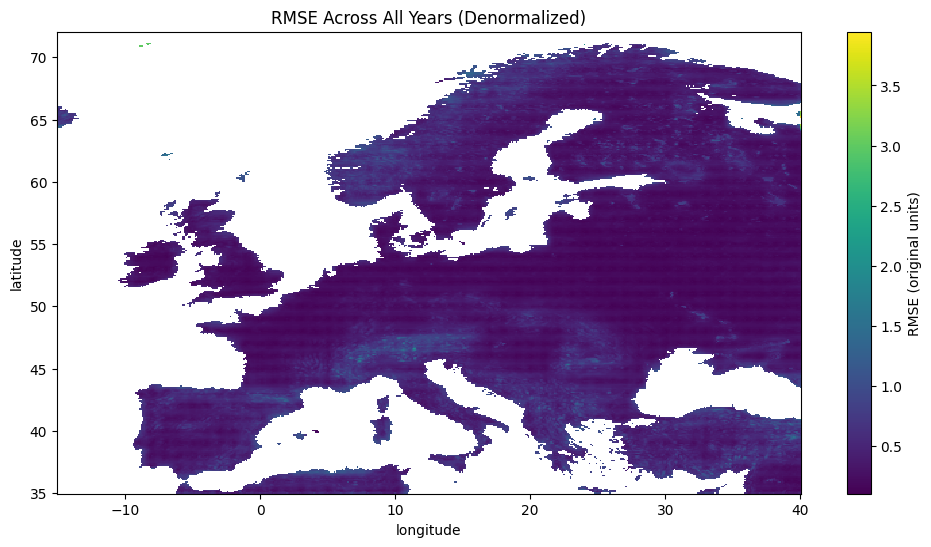

TypeError: unsupported format string passed to Array.__format__

In [ ]:
# RMSE Map
mse_maps = []
sum_sq = 0
n_total = 0

for year in range(year_min, year_max + 1):
    file_nn = f"{path_NN}cerra_dm_{var}_{year}_lowres_values_in_highres_grid_output.nc"
    file_ref = f"{path_original}cerra_dm_{var}_{year}.nc"

    mse, squared_error, n = compute_statistic_year(file_nn, file_ref, var_file, 'mse')
    mse_maps.append(mse)
    sum_sq += squared_error.sum()
    n_total += n.sum()

rmse_map = np.sqrt(xr.concat(mse_maps, dim='year').mean(dim='year'))
rmse_map.plot(
    figsize=(12, 6),
    cbar_kwargs={'label': 'RMSE (original units)'},
    cmap='viridis'
)
plt.title('RMSE Across All Years (Denormalized)')
plt.show()

rmse = np.sqrt(sum_sq / n_total)
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} (original units)")

/home/u/u244085/trees-in-the-city/.venv/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


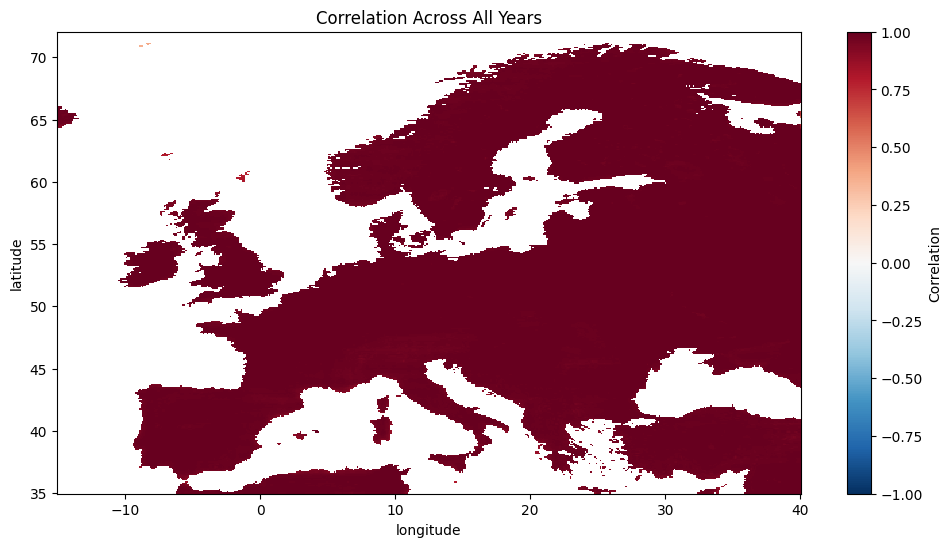

In [ ]:
# Correlation Map
correlation_maps = []

for year in range(year_min, year_max + 1):
    file_nn = f"{path_NN}cerra_dm_{var}_{year}_lowres_values_in_highres_grid_output.nc"
    file_ref = f"{path_original}cerra_dm_{var}_{year}.nc"

    correlation = compute_statistic_year(file_nn, file_ref, var_file, 'correlation')
    correlation_maps.append(correlation)

correlation_map = xr.concat(correlation_maps, dim='year').mean(dim='year')
correlation_map.plot(
    figsize=(12, 6),
    cbar_kwargs={'label': 'Correlation'},
    cmap='RdBu_r', vmin=-1, vmax=1
)
plt.title('Correlation Across All Years')
plt.show()

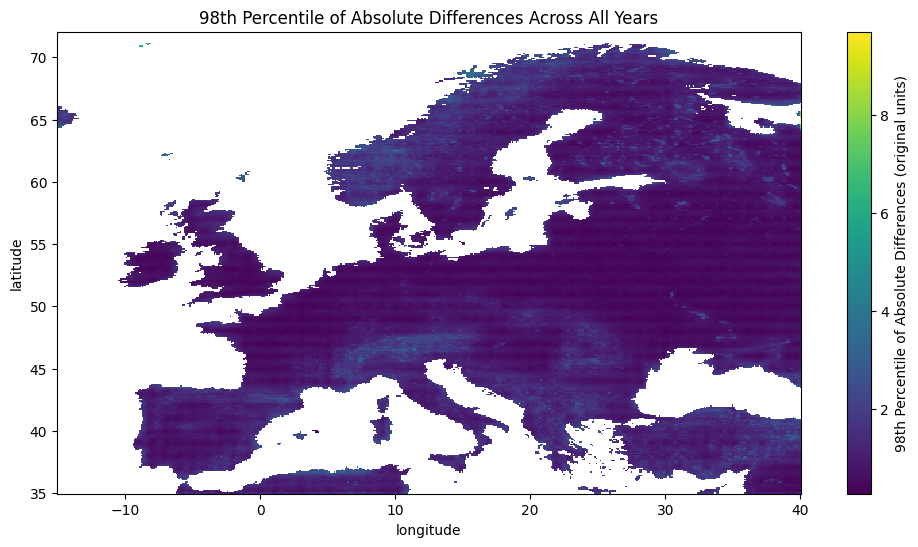

In [ ]:
# 98th Percentile Map
p98_maps = []

for year in range(year_min, year_max + 1):
    file_nn = f"{path_NN}cerra_dm_{var}_{year}_lowres_values_in_highres_grid_output.nc"
    file_ref = f"{path_original}cerra_dm_{var}_{year}.nc"

    p98_abs_diff = compute_statistic_year(file_nn, file_ref, var_file, 'p98_abs_diff')
    p98_maps.append(p98_abs_diff)

p98_map = xr.concat(p98_maps, dim='year').mean(dim='year')
p98_map.plot(
    figsize=(12, 6),
    cbar_kwargs={'label': '98th Percentile of Absolute Differences (original units)'},
    cmap='viridis'
)
plt.title('98th Percentile of Absolute Differences Across All Years')
plt.show()

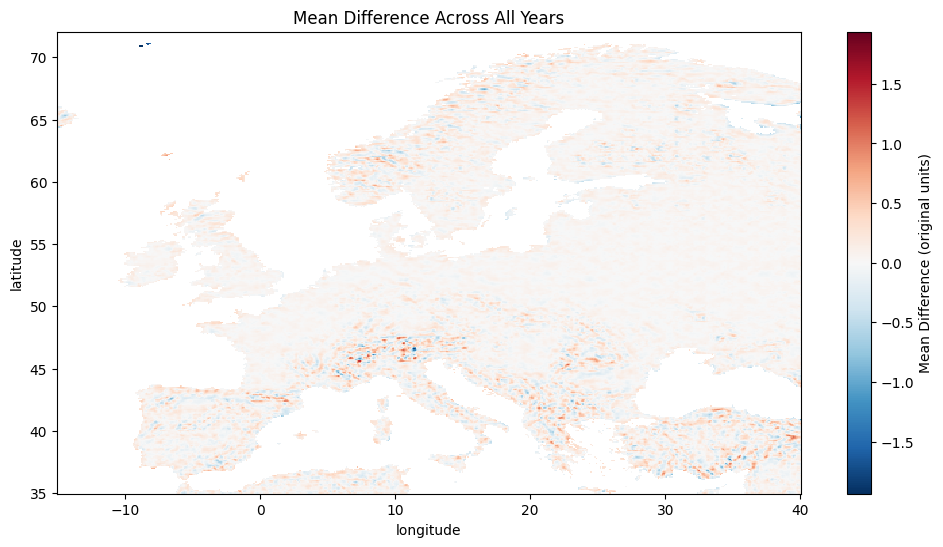

In [ ]:
# Mean Difference Map
mean_diff_maps = []

for year in range(year_min, year_max + 1):
    file_nn = f"{path_NN}cerra_dm_{var}_{year}_lowres_values_in_highres_grid_output.nc"
    file_ref = f"{path_original}cerra_dm_{var}_{year}.nc"

    mean_diff = compute_statistic_year(file_nn, file_ref, var_file, 'mean_diff')
    mean_diff_maps.append(mean_diff)

mean_diff_map = xr.concat(mean_diff_maps, dim='year').mean(dim='year')
mean_diff_map.plot(
    figsize=(12, 6),
    cbar_kwargs={'label': 'Mean Difference (original units)'},
    cmap='RdBu_r'
)
plt.title('Mean Difference Across All Years')
plt.show()

/home/u/u244085/trees-in-the-city/.venv/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


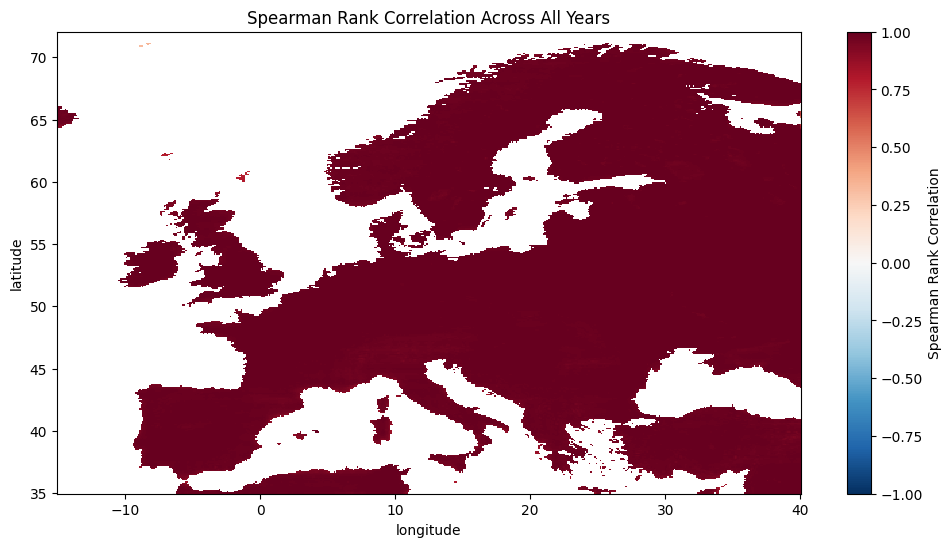

In [ ]:
# Spearman Rank Correlation Map
spearman_maps = []

for year in range(year_min, year_max + 1):
    file_nn = f"{path_NN}cerra_dm_{var}_{year}_lowres_values_in_highres_grid_output.nc"
    file_ref = f"{path_original}cerra_dm_{var}_{year}.nc"

    spearman = compute_statistic_year(file_nn, file_ref, var_file, 'spearman')
    spearman_maps.append(spearman)

spearman_map = xr.concat(spearman_maps, dim='year').mean(dim='year')
spearman_map.plot(
    figsize=(12, 6),
    cbar_kwargs={'label': 'Spearman Rank Correlation'},
    cmap='RdBu_r', vmin=-1, vmax=1
)
plt.title('Spearman Rank Correlation Across All Years')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import scipy.stats as stats
from scipy.stats import gaussian_kde

# --- Configuration ---
var = 't2max'
var_file = 't2m'
year_min = 2012
year_max = 2016
year_ref_min = 1985
year_ref_max = 2014
chunks = {"time": 30, "lat": 150, "lon": 150}

# --- Helper Functions ---
def remove_leap_days(ds):
    day_of_year = ds['time'].dt.dayofyear
    ds_corrected = ds.sel(time=day_of_year <= 365)
    return ds_corrected

def load_and_align(file_nn, file_ref, var_file):
    # Load reference data
    ds_ref = xr.open_dataset(file_ref, chunks=chunks)[var_file]
    ds_ref = remove_leap_days(ds_ref)

    # Load NN output
    ds_nn = xr.open_dataset(file_nn, chunks=chunks)[var_file]
    ds_nn['time'] = ds_ref['time']

    # Align datasets
    ds_nn, ds_ref = xr.align(ds_nn, ds_ref)

    # Mask ocean data (where reference is NaN)
    ds_nn_denormalized = xr.where(np.isnan(ds_ref), np.nan, ds_nn)

    return ds_ref, ds_nn_denormalized

# --- Paths ---
path_original = f'/work/uo1075/u241308/data_python_PostDoc/BB_challenge/data/era5_land/{var}/highres/anomalies/'
path_NN = '/work/uo1075/u244085/trees_in_the_city/ML_downscaling/Physics-Informed-CNN-Reconstructions/evaluations/t2m/era5_land_HR_anomaly_5Layer/data/'

# --- Load and Concatenate Data for All Years ---
all_ref_values = []
all_nn_values = []

for year in range(year_min, year_max + 1):
    file_nn = f"{path_NN}era5_land_{var}_daily_{year}_europe_anomalies_ref_{year_ref_min}_{year_ref_max}_lowres_values_in_highres_grid_output.nc"
    file_ref = f"{path_original}era5_land_{var}_daily_{year}_europe_anomalies_ref_{year_ref_min}_{year_ref_max}.nc"

    ds_ref, ds_nn_denorm = load_and_align(file_nn, file_ref, var_file)

    # Flatten and store values
    ref_values = ds_ref.values.flatten()
    nn_values = ds_nn_denorm.values.flatten()

    # Remove NaN values
    ref_values = ref_values[~np.isnan(ref_values)]
    nn_values = nn_values[~np.isnan(nn_values)]

    all_ref_values.extend(ref_values)
    all_nn_values.extend(nn_values)

# Convert to numpy arrays
all_ref_values = np.array(all_ref_values)
all_nn_values = np.array(all_nn_values)

# --- Plot Histograms ---
# plt.figure(figsize=(12, 6))
# plt.hist(all_ref_values, bins=50, alpha=0.5, label='Reference', density=True, edgecolor='black')
# plt.hist(all_nn_values, bins=50, alpha=0.5, label='NN Output', density=True, edgecolor='black')
# plt.title('Histogram: Reference vs NN Output')
# plt.xlabel('Value')
# plt.ylabel('Density')
# plt.legend()
# plt.grid(True)
# plt.savefig('histogram_comparison.png', dpi=200, bbox_inches='tight')
# plt.show()

# --- Plot PDFs (Kernel Density Estimation) ---
plt.figure(figsize=(12, 6))
kde_ref = gaussian_kde(all_ref_values)
kde_nn = gaussian_kde(all_nn_values)
x_grid = np.linspace(min(all_ref_values.min(), all_nn_values.min()),
                     max(all_ref_values.max(), all_nn_values.max()), 1000)
plt.plot(x_grid, kde_ref(x_grid), label='Reference', color='blue', linewidth=2)
plt.plot(x_grid, kde_nn(x_grid), label='NN Output', color='orange', linewidth=2)
plt.title('PDF: Reference vs NN Output')
plt.xlabel('Value')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.savefig('pdf_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

# --- Optional: Q-Q Plot for Direct Comparison ---
plt.figure(figsize=(10, 6))
stats.probplot(all_ref_values, dist="norm", plot=plt)
plt.title("Q-Q Plot: Reference Data")
plt.savefig('qq_plot_reference.png', dpi=200, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 6))
stats.probplot(all_nn_values, dist="norm", plot=plt)
plt.title("Q-Q Plot: NN Output")
plt.savefig('qq_plot_nn.png', dpi=200, bbox_inches='tight')
plt.show()